<a href="https://colab.research.google.com/github/piyushk4732/cognitive_computing/blob/main/Assignment_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Original paragraph:\n Cricket is my favourite sport because every match has something interesting to watch. I like seeing how batters handle pressure and how bowlers try different ways to take wickets. A good partnership can change the direction of a match, but one brilliant catch can do the same. I enjoy all three formats because Test matches need patience, ODIs require balance, and T20 games are full of quick action. Cricket is also a team game, so every player has to do their part. For me, that mix of skill, planning, and excitement makes cricket special.
\nLowercase text without punctuation:\n cricketismyfavouritesportbecauseeverymatchhassomethinginterestingtowatchilikeseeinghowbattershandlepressureandhowbowlerstrydifferentwaystotakewicketsagoodpartnershipcanchangethedirectionofamatchbutonebrilliantcatchcandothesameienjoyallthreeformatsbecausetestmatchesneedpatienceodisrequirebalanceandt20gamesarefullofquickactioncricketisalsoateamgamesoeveryplayerhastodotheirpartformethatmixofskil

/tmp/ipykernel_1537/461385833.py:44: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


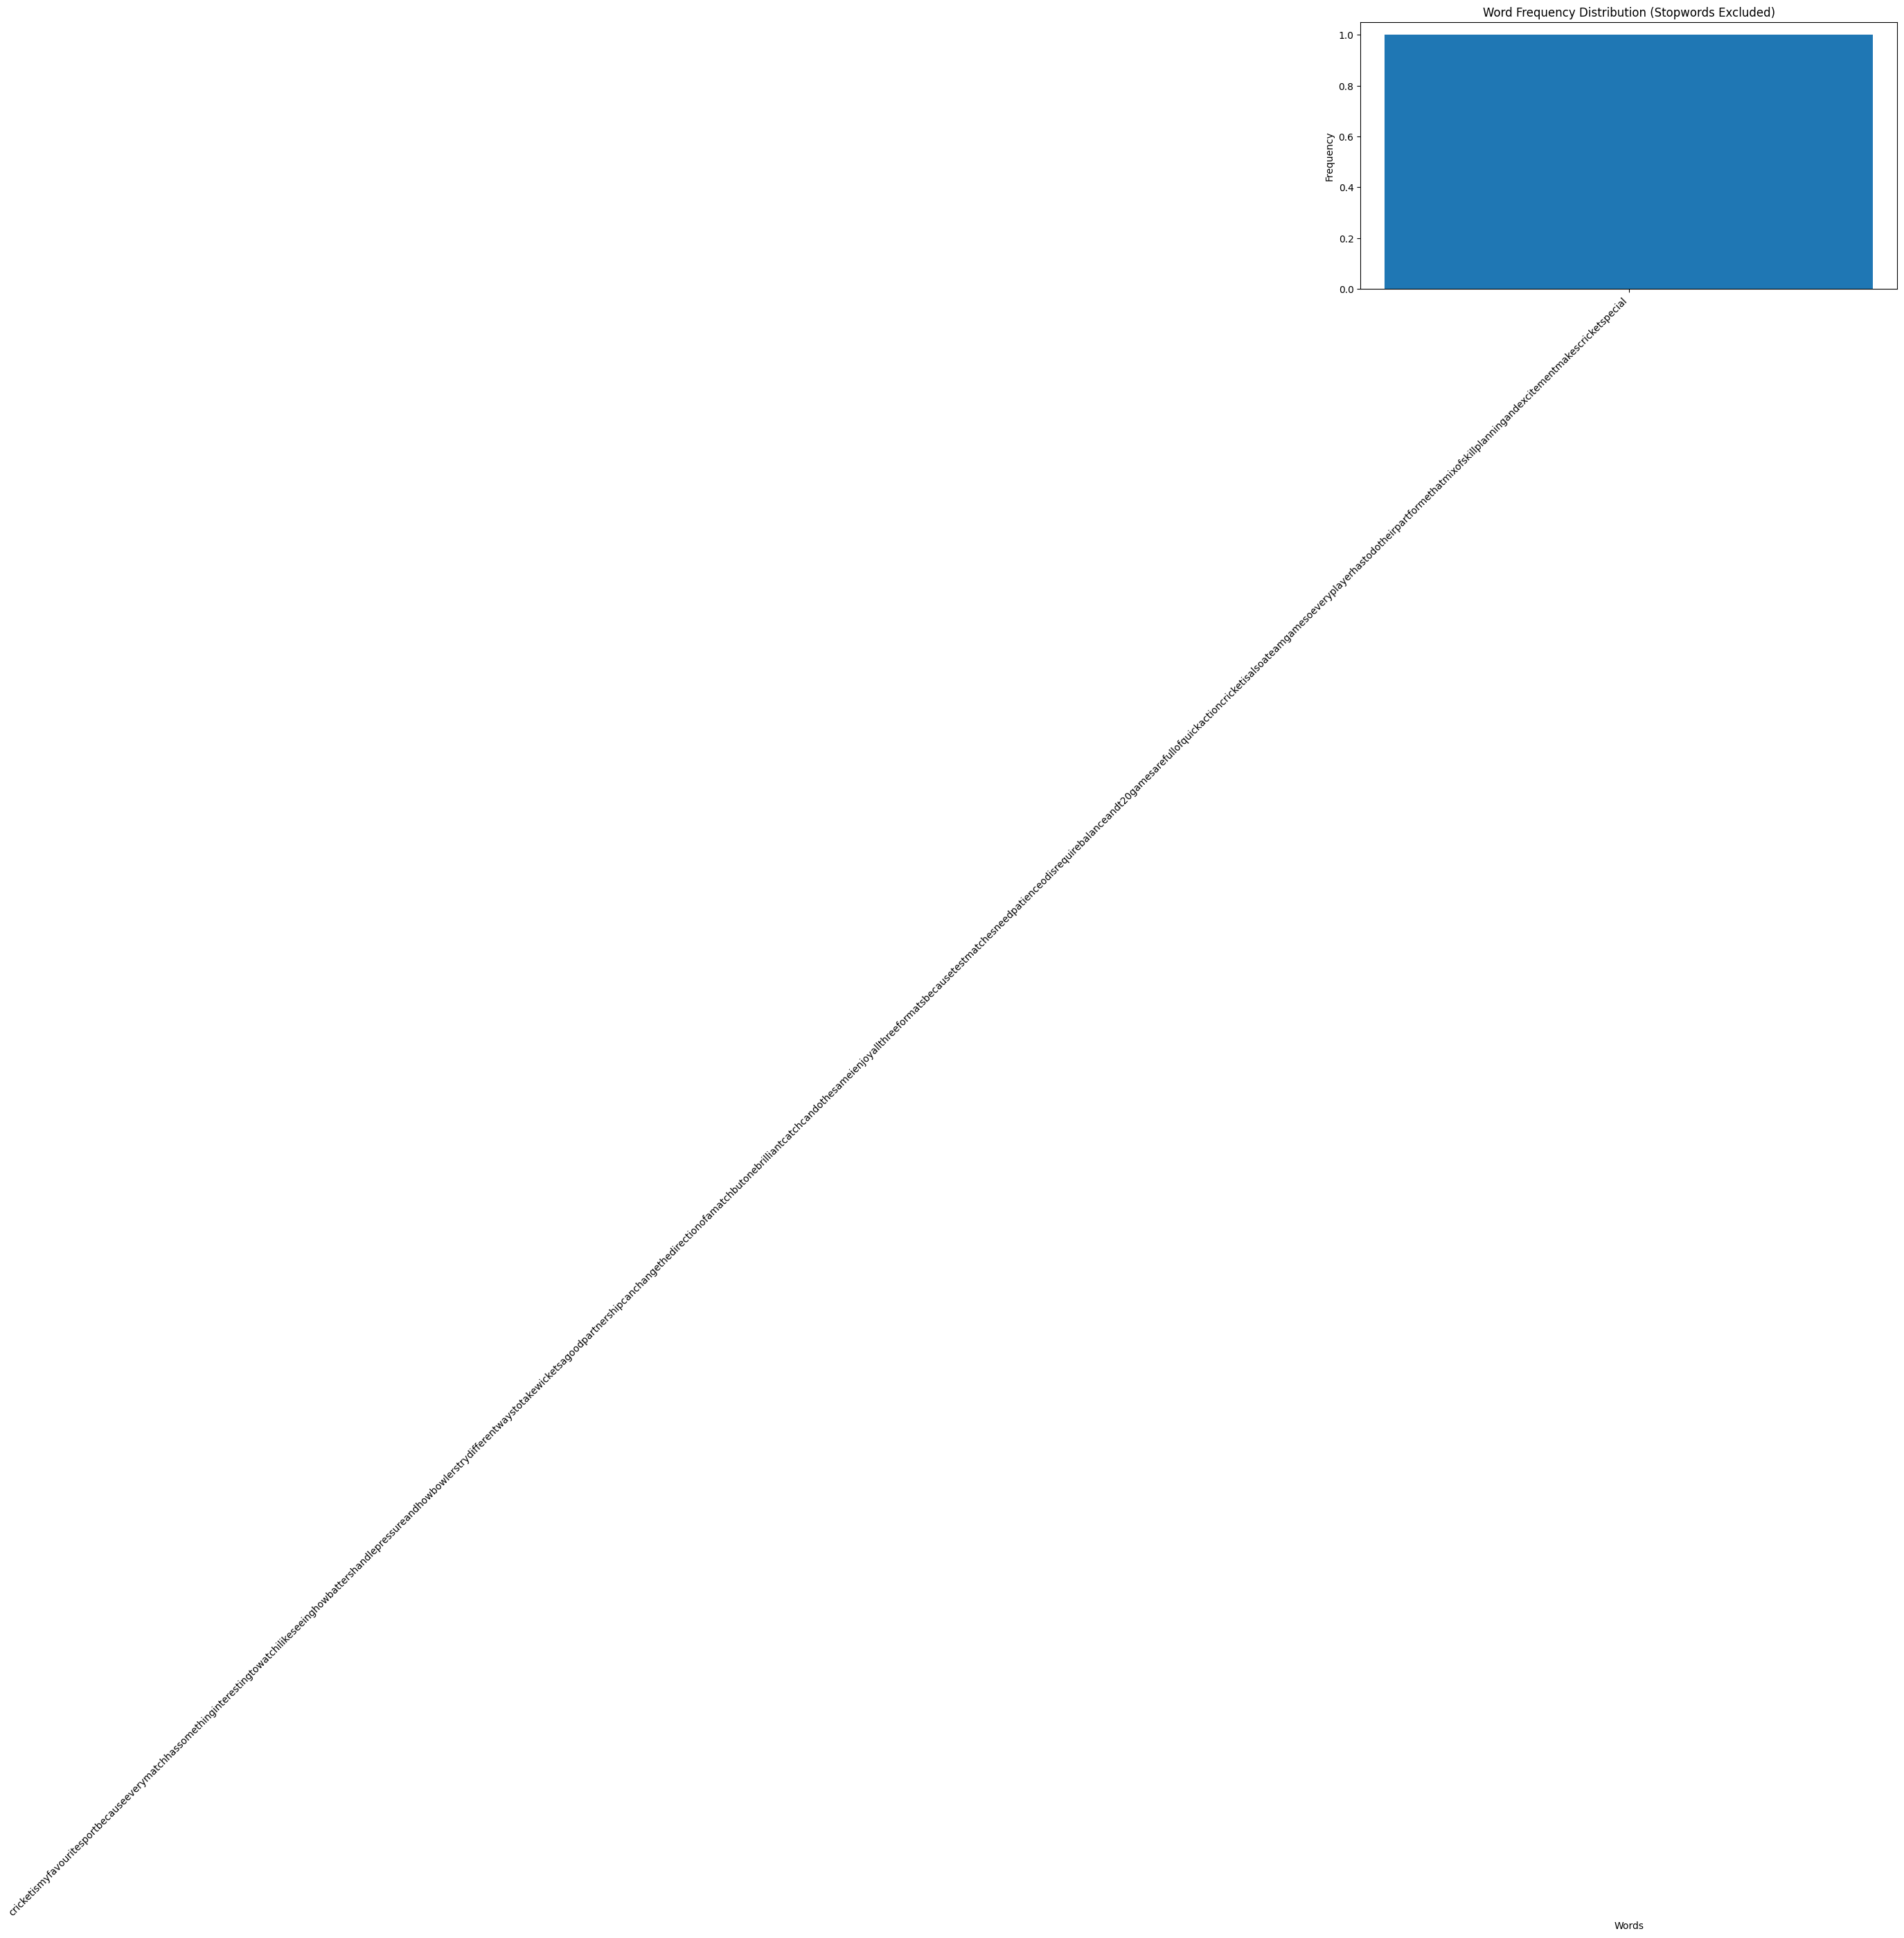

In [6]:
paragraph = "Cricket is my favourite sport because every match has something interesting to watch. I like seeing how batters handle pressure and how bowlers try different ways to take wickets. A good partnership can change the direction of a match, but one brilliant catch can do the same. I enjoy all three formats because Test matches need patience, ODIs require balance, and T20 games are full of quick action. Cricket is also a team game, so every player has to do their part. For me, that mix of skill, planning, and excitement makes cricket special."

import re
import nltk
from collections import Counter
import matplotlib.pyplot as plt

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

clean_text = re.sub(r'[^a-zA-Z0-9\\s]', '', paragraph.lower())
print("Original paragraph:\\n", paragraph)
print("\\nLowercase text without punctuation:\\n", clean_text)

split_words = clean_text.split()
nltk_words = nltk.word_tokenize(clean_text)

print("\\nWords using split():\\n", split_words)
print("\\nWords using NLTK word_tokenize():\\n", nltk_words)
print("\\nNumber of words using split():", len(split_words))
print("Number of words using word_tokenize():", len(nltk_words))
print("\\nThe split() method simply breaks the text wherever it finds whitespace. NLTK's word_tokenize() is designed for language processing and can handle punctuation as separate tokens. Since punctuation has already been removed in this example, both methods give almost the same result.")

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))
filtered_words = [word for word in nltk_words if word not in stop_words]
print("\\nWords after stopword removal:\\n", filtered_words)

word_counts = Counter(filtered_words)
print("\\nWord frequency distribution:")
for word, frequency in word_counts.most_common():
    print(f"{word}: {frequency}")

plt.figure(figsize=(10, 5))
plt.bar(word_counts.keys(), word_counts.values())
plt.xticks(rotation=45, ha='right')
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.title("Word Frequency Distribution (Stopwords Excluded)")
plt.tight_layout()
plt.show()

## Q2. Word extraction, stopword removal, stemming, and lemmatization

In [7]:
alphabetic_words = re.findall(r'\\b[a-zA-Z]+\\b', paragraph.lower())
print("Words containing only alphabets:\\n", alphabetic_words)

filtered_alpha_words = [word for word in alphabetic_words if word not in stop_words]
print("\\nAfter stopword removal:\\n", filtered_alpha_words)

from nltk.stem import PorterStemmer, WordNetLemmatizer

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed_words = [stemmer.stem(word) for word in filtered_alpha_words]
lemmatized_words = [lemmatizer.lemmatize(word) for word in filtered_alpha_words]

comparison = list(zip(filtered_alpha_words, stemmed_words, lemmatized_words))
print("\\nOriginal | Stemmed | Lemmatized")
for original, stemmed, lemmatized in comparison:
    print(f"{original:15} | {stemmed:15} | {lemmatized}")

print("\\nStemming cuts words down to a shorter form, so the result is not always a proper English word. Lemmatization tries to find the actual base form of a word. I would use stemming when I only need to compare words quickly, but I would prefer lemmatization when the output should be easier to read and understand.")

Words containing only alphabets:\n []
\nAfter stopword removal:\n []
\nOriginal | Stemmed | Lemmatized
\nStemming cuts words down to a shorter form, so the result is not always a proper English word. Lemmatization tries to find the actual base form of a word. I would use stemming when I only need to compare words quickly, but I would prefer lemmatization when the output should be easier to read and understand.


## Q3. Bag of Words and TF-IDF

Three original short texts are used as a small collection.

In [8]:
texts = [
    "The cricket team won the match with excellent batting and bowling.",
    "A new smartphone offers a sharp camera, fast processor, and long battery life.",
    "The restaurant serves fresh food with friendly service and affordable prices."
]

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

count_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = count_vectorizer.fit_transform(texts)

print("Bag of Words feature names:")
print(count_vectorizer.get_feature_names_out())
print("\\nBag of Words matrix:")
print(bow_matrix.toarray())

tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
feature_names = tfidf_vectorizer.get_feature_names_out()

print("\\nTF-IDF matrix:")
print(np.round(tfidf_matrix.toarray(), 3))

for index, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[-3:][::-1]
    top_keywords = [(feature_names[i], round(row[i], 3)) for i in top_indices if row[i] > 0]
    print(f"\\nText {index} top 3 TF-IDF keywords:")
    for word, score in top_keywords:
        print(f"{word}: {score}")

Bag of Words feature names:
['affordable' 'battery' 'batting' 'bowling' 'camera' 'cricket' 'excellent'
 'fast' 'food' 'fresh' 'friendly' 'life' 'long' 'match' 'new' 'offers'
 'prices' 'processor' 'restaurant' 'serves' 'service' 'sharp' 'smartphone'
 'team' 'won']
\nBag of Words matrix:
[[0 0 1 1 0 1 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 1 1]
 [0 1 0 0 1 0 0 1 0 0 0 1 1 0 1 1 0 1 0 0 0 1 1 0 0]
 [1 0 0 0 0 0 0 0 1 1 1 0 0 0 0 0 1 0 1 1 1 0 0 0 0]]
\nTF-IDF matrix:
[[0.    0.    0.378 0.378 0.    0.378 0.378 0.    0.    0.    0.    0.
  0.    0.378 0.    0.    0.    0.    0.    0.    0.    0.    0.    0.378
  0.378]
 [0.    0.316 0.    0.    0.316 0.    0.    0.316 0.    0.    0.    0.316
  0.316 0.    0.316 0.316 0.    0.316 0.    0.    0.    0.316 0.316 0.
  0.   ]
 [0.354 0.    0.    0.    0.    0.    0.    0.    0.354 0.354 0.354 0.
  0.    0.    0.    0.    0.354 0.    0.354 0.354 0.354 0.    0.    0.
  0.   ]]
\nText 1 top 3 TF-IDF keywords:
won: 0.378
team: 0.378
cricket: 0.378
\nText

## Q4. Jaccard and cosine similarity between two technologies

In [13]:


import re
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

technology_texts = [
    "Artificial intelligence uses data and algorithms to learn patterns, make predictions, and automate decisions. Machine learning and neural networks are common AI techniques. AI is used in healthcare, education, transport, and recommendation systems.",
    "Blockchain is a distributed digital ledger that stores records in linked blocks. Cryptography and network consensus help protect transactions. Blockchain is used in digital currencies, supply chains, and secure record management."
]

technology_names = ["Artificial Intelligence", "Blockchain"]

stop_words = set(stopwords.words('english'))

technology_tokens = []

for text_value in technology_texts:
    processed = re.findall("[a-zA-Z]+", text_value.lower())
    processed = [word for word in processed if word not in stop_words]
    technology_tokens.append(processed)

for name, tokens in zip(technology_names, technology_tokens):
    print(name, "tokens:", tokens)

set_a = set(technology_tokens[0])
set_b = set(technology_tokens[1])

intersection_words = set_a.intersection(set_b)
union_words = set_a.union(set_b)

jaccard_similarity = len(intersection_words) / len(union_words) if union_words else 0

print("\nJaccard Similarity:", round(jaccard_similarity, 4))

technology_tfidf = TfidfVectorizer(stop_words='english')
technology_matrix = technology_tfidf.fit_transform(technology_texts)

cosine_score = cosine_similarity(
    technology_matrix[0:1],
    technology_matrix[1:2]
)[0][0]

print("Cosine Similarity:", round(float(cosine_score), 4))

print("\nAnalysis:")
print("Jaccard similarity compares the common unique words between the two texts.")
print("Cosine similarity compares the TF-IDF weighted words and considers their importance.")
print("Cosine similarity gives more useful insights here because it considers the importance of words rather than just checking whether words are common.")



Artificial Intelligence tokens: ['artificial', 'intelligence', 'uses', 'data', 'algorithms', 'learn', 'patterns', 'make', 'predictions', 'automate', 'decisions', 'machine', 'learning', 'neural', 'networks', 'common', 'ai', 'techniques', 'ai', 'used', 'healthcare', 'education', 'transport', 'recommendation', 'systems']
Blockchain tokens: ['blockchain', 'distributed', 'digital', 'ledger', 'stores', 'records', 'linked', 'blocks', 'cryptography', 'network', 'consensus', 'help', 'protect', 'transactions', 'blockchain', 'used', 'digital', 'currencies', 'supply', 'chains', 'secure', 'record', 'management']

Jaccard Similarity: 0.0227
Cosine Similarity: 0.0191

Analysis:
Jaccard similarity compares the common unique words between the two texts.
Cosine similarity compares the TF-IDF weighted words and considers their importance.
Cosine similarity gives more useful insights here because it considers the importance of words rather than just checking whether words are common.


## Q5. Product review sentiment analysis and word cloud

Review: This phone has an excellent camera and the battery lasts all day. I am very happy with this purchase.
Polarity: 1.0 | Sentiment: Positive

Review: The display is beautiful, performance is smooth, and the design feels premium.
Polarity: 0.625 | Sentiment: Positive

Review: The product is average. It works as expected but nothing makes it special.
Polarity: 0.036 | Sentiment: Neutral

Review: The battery drains quickly and the phone becomes hot. I am disappointed with the poor performance.
Polarity: -0.142 | Sentiment: Negative

Review: Terrible customer service and a faulty product. I would not recommend it.
Polarity: -1.0 | Sentiment: Negative



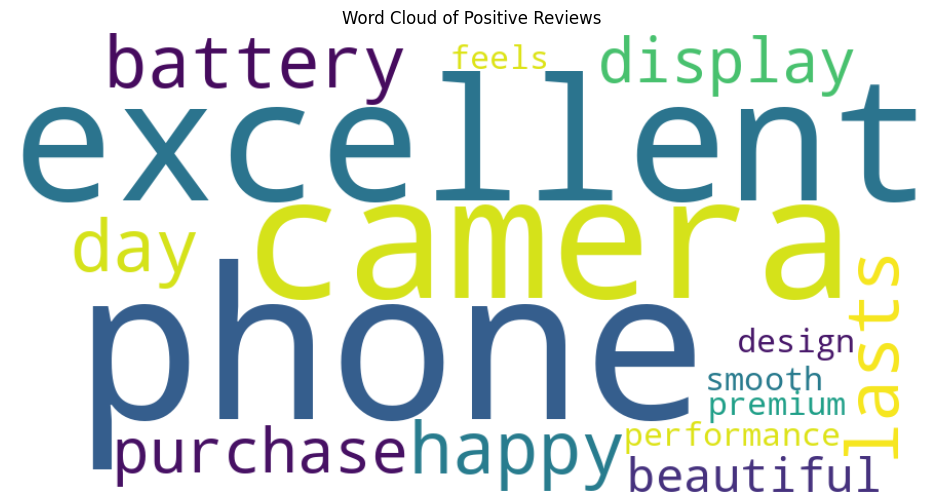

TextBlob gives each review a polarity score between -1 and +1. A score above 0.1 is treated as positive, a score below -0.1 as negative, and anything in between is treated as neutral. These limits are simple rules for this assignment, so a different choice of limits could change some results.


In [11]:
reviews = [
    "This phone has an excellent camera and the battery lasts all day. I am very happy with this purchase.",
    "The display is beautiful, performance is smooth, and the design feels premium.",
    "The product is average. It works as expected but nothing makes it special.",
    "The battery drains quickly and the phone becomes hot. I am disappointed with the poor performance.",
    "Terrible customer service and a faulty product. I would not recommend it."
]

from textblob import TextBlob

sentiment_results = []
positive_reviews = []

for review in reviews:
    polarity = TextBlob(review).sentiment.polarity
    if polarity > 0.1:
        label = "Positive"
        positive_reviews.append(review)
    elif polarity < -0.1:
        label = "Negative"
    else:
        label = "Neutral"
    sentiment_results.append((review, polarity, label))

for review, polarity, label in sentiment_results:
    print("Review:", review)
    print("Polarity:", round(polarity, 3), "| Sentiment:", label)
    print()

from wordcloud import WordCloud

positive_text = " ".join(positive_reviews)
if positive_text.strip():
    wordcloud = WordCloud(width=900, height=450, background_color='white').generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title("Word Cloud of Positive Reviews")
    plt.show()
else:
    print("No positive reviews were found, so a word cloud cannot be generated.")

print("TextBlob gives each review a polarity score between -1 and +1. A score above 0.1 is treated as positive, a score below -0.1 as negative, and anything in between is treated as neutral. These limits are simple rules for this assignment, so a different choice of limits could change some results.")

## Q6. Text generation using a Keras LSTM




In [12]:
training_text = """Cricket is a game where every player has a job to do. Batters try to score runs while choosing the right shots and avoiding risky decisions. Bowlers work on their line and length to stop runs and take wickets. Fielders need to stay focused because a catch or a quick run-out can change the match. Teams practise together to improve their skills and understand each other's strengths. The captain also has to make decisions based on the score, pitch, and match situation. Fans bring energy to the game by supporting their teams. Winning is enjoyable, but players can learn a lot from a loss too. Cricket teaches teamwork, patience, and discipline."""

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
import numpy as np
import tensorflow as tf

tf.random.set_seed(42)
np.random.seed(42)

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in training_text.lower().split('.'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[:i + 1])

max_sequence_len = max(len(sequence) for sequence in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre')

X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Vocabulary size:", total_words)
print("Number of training sequences:", len(input_sequences))
print("Maximum sequence length:", max_sequence_len)

model = Sequential([
    Embedding(total_words, 64, input_length=max_sequence_len - 1),
    LSTM(100),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history = model.fit(X, y, epochs=120, verbose=0)
print("Final training accuracy:", round(float(history.history['accuracy'][-1]), 4))

def generate_text(seed_word, next_words=30):
    output_text = seed_word.lower()
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = token_list[-(max_sequence_len - 1):]
        token_list = pad_sequences([token_list], maxlen=max_sequence_len - 1, padding='pre')
        predicted_probabilities = model.predict(token_list, verbose=0)[0]
        predicted_id = int(np.argmax(predicted_probabilities))
        predicted_word = tokenizer.index_word.get(predicted_id, "")
        if not predicted_word or predicted_word == "<OOV>":
            break
        output_text += " " + predicted_word
    return output_text

seed_word = "cricket"
generated_text = generate_text(seed_word, 30)
print("Generated text:")
print(generated_text)

Vocabulary size: 81
Number of training sequences: 103
Maximum sequence length: 17


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Final training accuracy: 0.9417
Generated text:
cricket is game game where every player player has a job to do too too too too too match match match out change decisions match and their other's situation decisions decisions
